In [ ]:
import string
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.metrics import ConfusionMatrixDisplay

In [ ]:
# 62 clases: 0-9, A-Z, a-z
class_names = list(string.digits + string.ascii_uppercase + string.ascii_lowercase)

# Tu carga exacta con batch_size=32
train_ds, test_ds = tfds.load(
'emnist/byclass',
split=['train', 'test'],
shuffle_files=True,
as_supervised=True,
batch_size=32,
)

# Normalizar (0 a 1) y transponer para enderezar las letras de EMNIST
def preprocesar(imagen, etiqueta):
    imagen = tf.cast(imagen, tf.float32) / 255.0
    imagen = tf.transpose(imagen, perm=[0, 2, 1, 3])
    return imagen, etiqueta

train_ds = train_ds.map(preprocesar).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.map(preprocesar).prefetch(tf.data.AUTOTUNE)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/byclass/incomplete.PDY97Z_3.1.0/emnist-train.tfrecord-[0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/byclass/incomplete.PDY97Z_3.1.0/emnist-test.tfrecord-[0-9][0-9][0-9…

Dataset emnist downloaded and prepared to /root/tensorflow_datasets/emnist/byclass/3.1.0. Subsequent calls will reuse this data.


In [ ]:
plt.figure(figsize=(12, 5))
for imagenes, etiquetas in train_ds.take(1):
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(imagenes[i].numpy().squeeze(), cmap="gray")
        plt.title(f"Clase: {class_names[etiquetas[i].numpy()]}")
        plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# 1. Muestra de prueba (~3,000 imágenes = 94 lotes de 32) para el espacio latente 2D
x_visual, y_visual = [], []
for imgs, lbls in test_ds.take(94):
    x_visual.append(imgs.numpy())
    y_visual.append(lbls.numpy())
x_visual = np.concatenate(x_visual)
y_visual = np.concatenate(y_visual)

# 2. Etiquetas reales de todo test_ds para la matriz de confusión
y_test_real = np.concatenate([lbls.numpy() for _, lbls in test_ds])

# 3. Un lote de prueba (32 imágenes) para predicciones individuales
for imgs_muestra, lbls_muestra in test_ds.take(1):
    imgs_muestra = imgs_muestra.numpy()
    lbls_muestra = lbls_muestra.numpy()

# Función reutilizable para evaluar cualquier modelo
def evaluar_modelo(modelo, historial, nombre_modelo):
    # A. Precisión en test
    loss, acc = modelo.evaluate(test_ds, verbose=0)
    print(f"=== {nombre_modelo} ===")
    print(f"Pérdida en prueba: {loss:.4f} | Precisión en prueba: {acc*100:.2f}%\n")

    # B. Curvas de aprendizaje (Loss y Accuracy)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(historial.history['loss'], label='Entrenamiento')
    axes[0].plot(historial.history['val_loss'], label='Prueba')
    axes[0].set_title(f'Pérdida - {nombre_modelo}')
    axes[0].set_xlabel('Épocas')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(historial.history['accuracy'], label='Entrenamiento')
    axes[1].plot(historial.history['val_accuracy'], label='Prueba')
    axes[1].set_title(f'Precisión - {nombre_modelo}')
    axes[1].set_xlabel('Épocas')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # C. Matriz de confusión (62x62)
    probs = modelo.predict(test_ds, verbose=0)
    y_pred = np.argmax(probs, axis=1)
    fig, ax = plt.subplots(figsize=(16, 16))
    ConfusionMatrixDisplay.from_predictions(
        y_test_real, y_pred, display_labels=class_names,
        cmap="Blues", include_values=False, ax=ax
    )
    plt.title(f"Matriz de Confusión - {nombre_modelo}")
    plt.grid(False)
    plt.tight_layout()
    plt.show()

    # D. Espacio Latente 2D
    extractor = tf.keras.Model(inputs=modelo.inputs, outputs=modelo.get_layer("rep_2d").output)
    puntos2d = extractor.predict(x_visual, verbose=0)
    plt.figure(figsize=(7, 6))
    sc = plt.scatter(puntos2d[:, 0], puntos2d[:, 1], c=y_visual, cmap="turbo", s=8, alpha=0.7)
    plt.title(f"Espacio Latente 2D - {nombre_modelo}")
    plt.xlabel("Neurona 1")
    plt.ylabel("Neurona 2")
    plt.colorbar(sc, label="Índice de clase (0-61)")
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.show()

    # E. Predicción de 5 imágenes
    preds_5 = modelo.predict(imgs_muestra[:5], verbose=0)
    fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))
    for i in range(5):
        axes[i].imshow(imgs_muestra[i].squeeze(), cmap="gray")
        p_idx = np.argmax(preds_5[i])
        axes[i].set_title(f"Real: {class_names[lbls_muestra[i]]}\nPred: {class_names[p_idx]} ({preds_5[i][p_idx]:.2f})")
        axes[i].axis("off")
    plt.tight_layout()
    plt.show()

    return acc

In [ ]:
model_1 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units=128, activation="relu"),
    tf.keras.layers.Dense(units=2, activation="linear", name="rep_2d"),
    tf.keras.layers.Dense(units=62, activation="softmax")
])

model_1.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_1.summary()
history_1 = model_1.fit(train_ds, epochs=5, validation_data=test_ds)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_2d (Dense)                  │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 62)             │           186 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,924 (394.23 KB)

 Trainable params: 100,924 (394.23 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
21811/21811 ━━━━━━━━━━━━━━━━━━━━ 207s 9ms/step - accuracy: 0.4992 - loss: 1.8068 - val_accuracy: 0.5661 - val_loss: 1.5506
Epoch 2/5
21811/21811 ━━━━━━━━━━━━━━━━━━━━ 205s 9ms/step - accuracy: 0.5819 - loss: 1.5030 - val_accuracy: 0.5922 - val_loss: 1.4669
Epoch 3/5
21811/21811 ━━━━━━━━━━━━━━━━━━━━ 212s 10ms/step - accuracy: 0.6021 - loss: 1.4401 - val_accuracy: 0.6008 - val_loss: 1.4335
Epoch 4/5
21811/21811 ━━━━━━━━━━━━━━━━━━━━ 201s 9ms/step - accuracy: 0.6124 - loss: 1.4073 - val_accuracy: 0.6098 - val_loss: 1.4108
Epoch 5/5
21811/21811 ━━━━━━━━━━━━━━━━━━━━ 200s 9ms/step - accuracy: 0.6189 - loss: 1.3861 - val_accuracy: 0.6156 - val_loss: 1.4032


=== Modelo 1: Pocas Capas ===
Pérdida en prueba: 1.4032 | Precisión en prueba: 61.56%



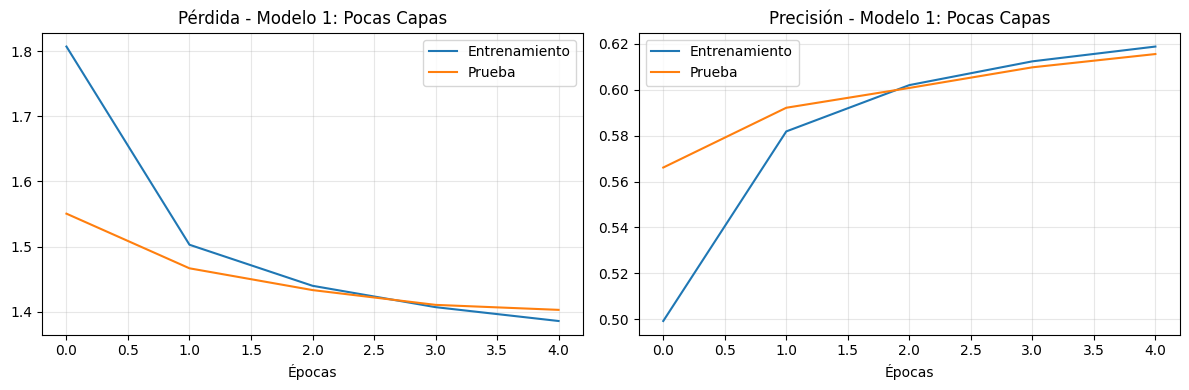

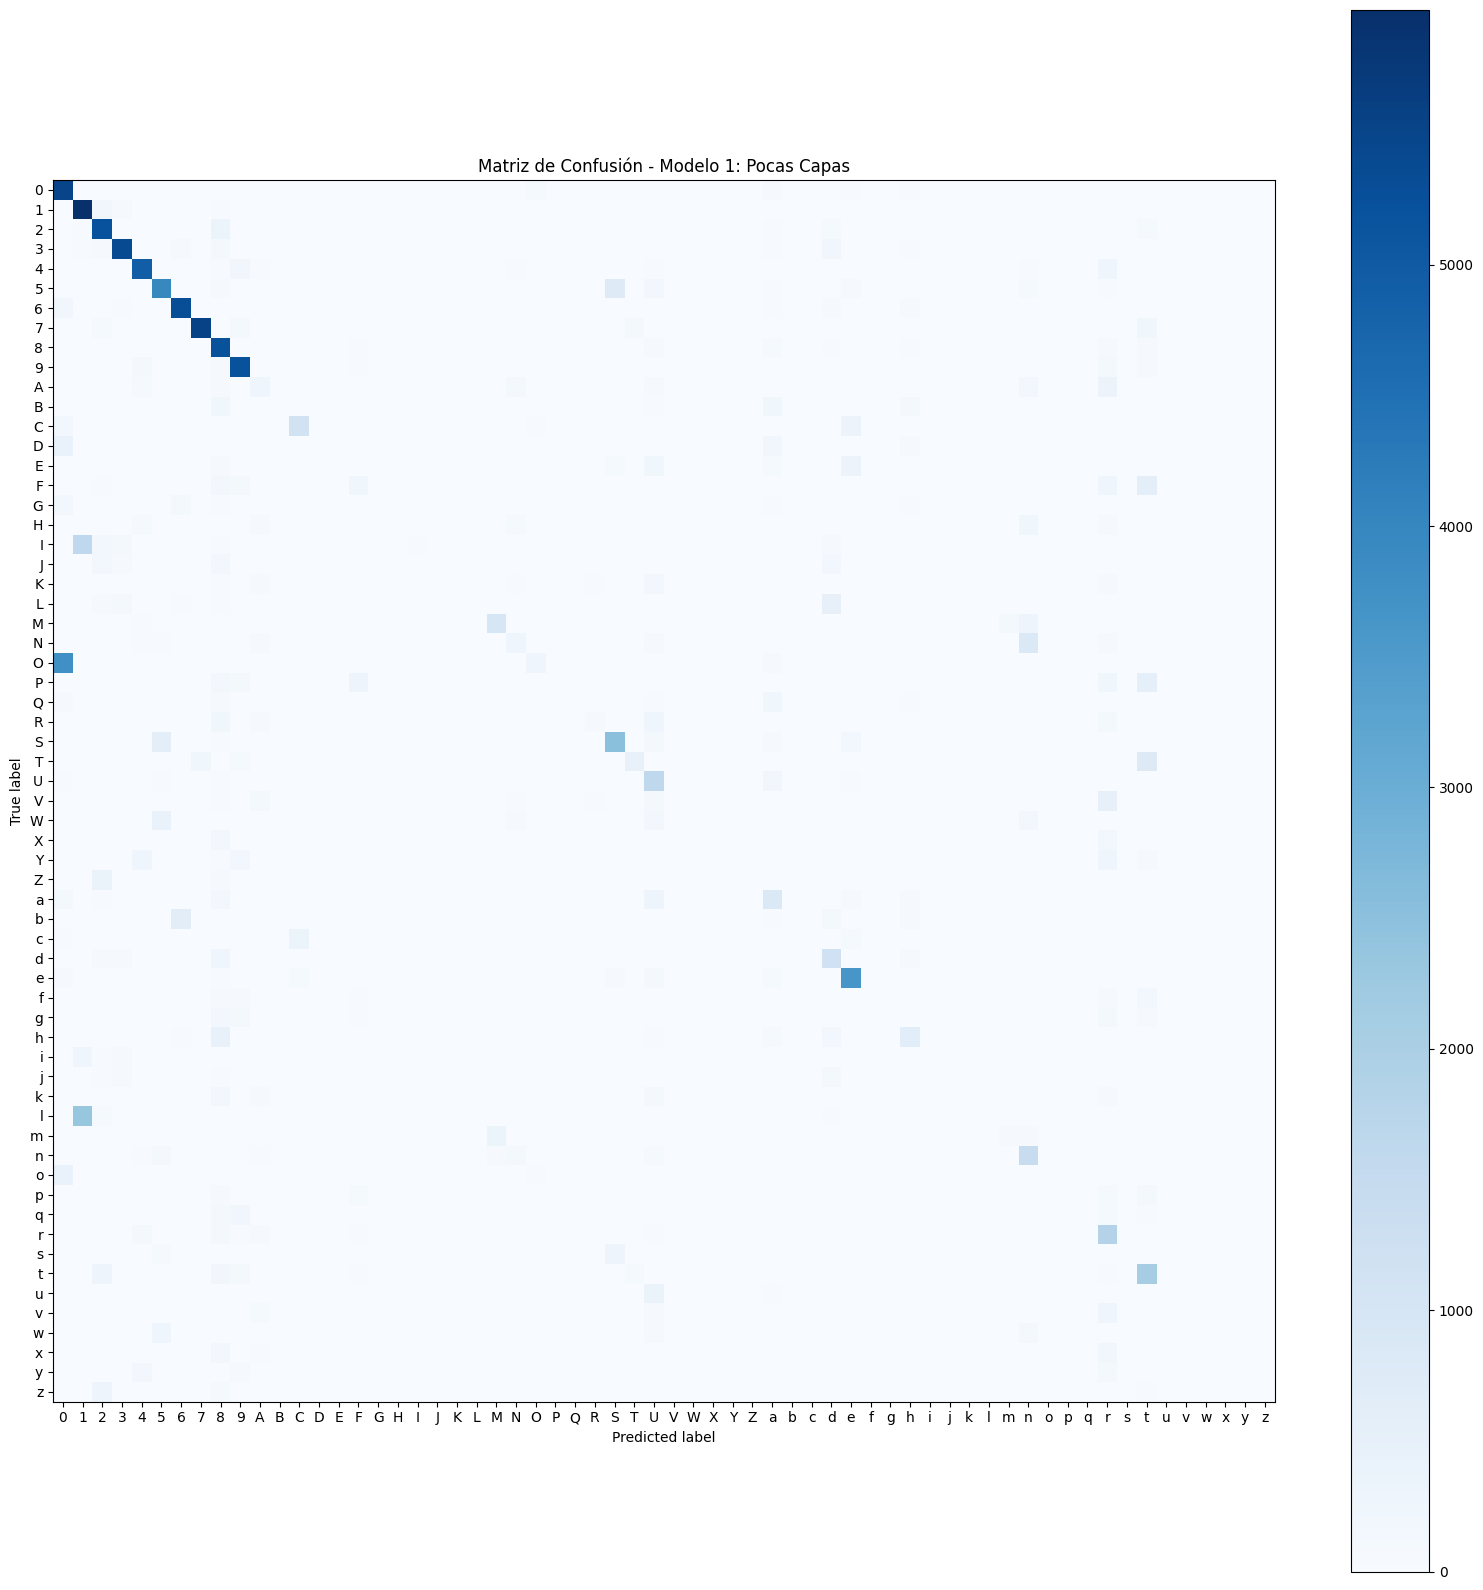

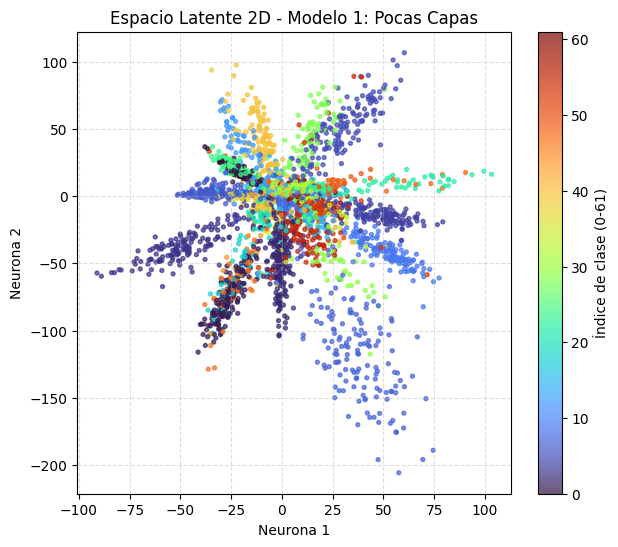

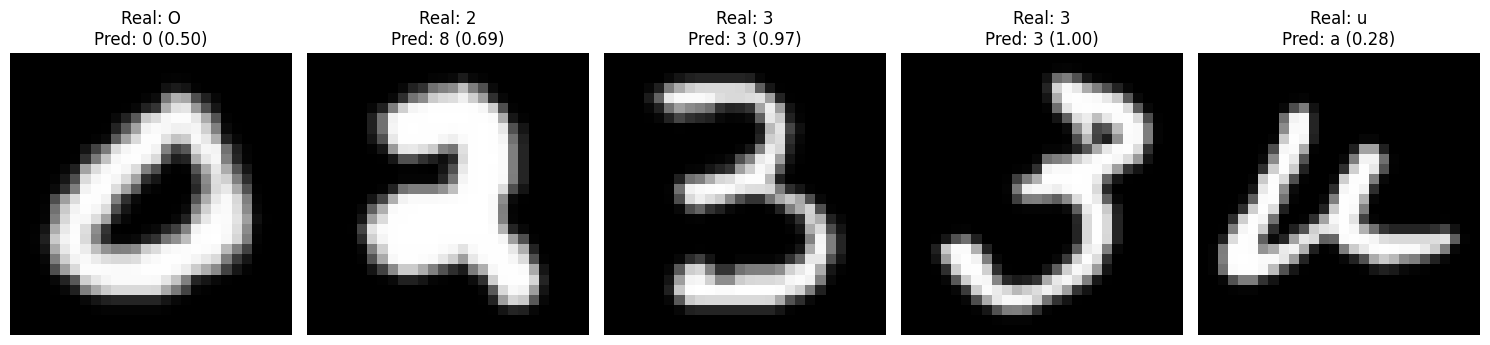

In [ ]:
acc_1 = evaluar_modelo(model_1, history_1, "Modelo 1: Pocas Capas")

In [8]:
model_conv = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    tf.keras.layers.MaxPool2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    tf.keras.layers.MaxPool2D((2, 2)),
    tf.keras.layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    tf.keras.layers.MaxPool2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units=64, activation="relu"),
    tf.keras.layers.Dense(units=2, activation="linear", name="rep_2d"),
    tf.keras.layers.Dense(units=62, activation="softmax")
])

model_conv.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_conv.summary()
history_conv = model_conv.fit(train_ds, epochs=5, validation_data=test_ds)

NameError: name 'tf' is not defined

In [ ]:
acc_conv = evaluar_modelo(model_conv, history_conv, "Modelo 2: Red Convolucional")

In [ ]:
model_3 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units=128, activation="relu"),
    tf.keras.layers.Dense(units=64, activation="relu"),
    tf.keras.layers.Dense(units=32, activation="relu"),
    tf.keras.layers.Dense(units=16, activation="relu"),
    tf.keras.layers.Dense(units=2, activation="linear", name="rep_2d"),
    tf.keras.layers.Dense(units=62, activation="softmax")
])

model_3.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_3.summary()
history_3 = model_3.fit(train_ds, epochs=5, validation_data=test_ds)

In [9]:
acc_3 = evaluar_modelo(model_3, history_3, "Modelo 3: Más Capas")

NameError: name 'evaluar_modelo' is not defined

In [ ]:
# Resumen comparativo de precisión
print("=== RESUMEN DE PRECISIÓN EN PRUEBA ===")
print(f"Modelo 1 (Pocas capas):       {acc_1*100:.2f}%")
print(f"Modelo 2 (Convolucional):     {acc_conv*100:.2f}%")
print(f"Modelo 3 (Más capas):         {acc_3*100:.2f}%\n")

# Predicción individual usando el mejor modelo (normalmente model_conv)
idx = 10 # Puedes cambiar este número entre 0 y 63
probs = model_conv.predict(imgs_muestra[idx:idx+1], verbose=0)[0]
clase_idx = np.argmax(probs)

print(f"Predicción: {class_names[clase_idx]} ({probs[clase_idx]*100:.2f}%)")
print(f"Clase real: {class_names[lbls_muestra[idx]]}")

plt.figure(figsize=(4, 4))
plt.imshow(imgs_muestra[idx].squeeze(), cmap="gray")
plt.title(f"Pred: {class_names[clase_idx]} ({probs[clase_idx]*100:.2f}%)\nReal: {class_names[lbls_muestra[idx]]}")
plt.axis("off")
plt.show()